# M01-2 | What Exactly prepare / convert Change in the Graph

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m01_hello_pt2e/02_graph_diff.ipynb)

M01-1 looked at the small stem section. This notebook switches to a complete small residual block
and lays out every change `prepare_pt2e` and `convert_pt2e` make to the graph.

Predict first, then run on to see the answers:

1. Is there an observer between conv2d and relu?
2. Do the input and output of `max_pool2d` use the same qparams?
3. What about the two inputs of `cat`?


In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m01_hello_pt2e")

In [2]:
import copy

import torch

from common.graph_utils import annotation_table, diff_ops, observer_placement_table, unannotated_ops
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. The Three Stages of a Residual Block

The model is `conv → bn → relu → conv → bn`, then added to the input `x` and passed through relu.
How conv → bn → relu changes was already seen in M01-1; here we draw only the residual-specific part: the input `x` feeds both the first conv and the `add`.


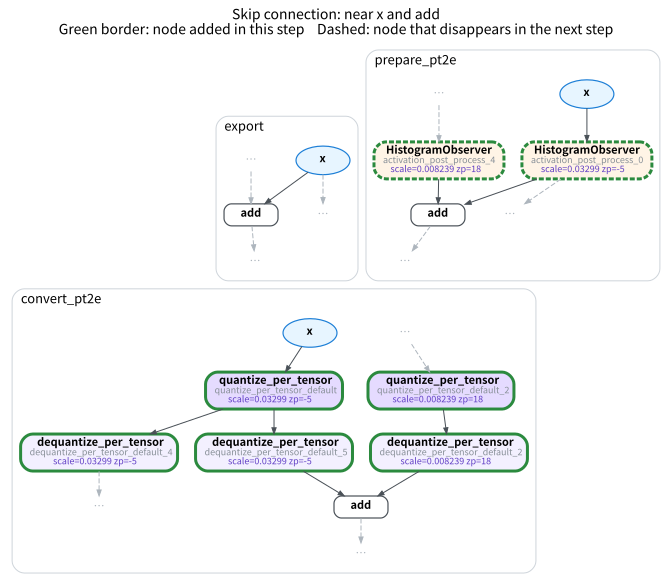

In [3]:
model = get_model("residual", ch=8).eval()
ex = (torch.randn(4, 8, 16, 16),)
gm = export_module(model, ex)

quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
with torch.no_grad():
    for _ in range(8):
        prepared(torch.randn(4, 8, 16, 16))
converted = convert_pt2e(copy.deepcopy(prepared))

draw_stages([(gm, "export"), (prepared, "prepare_pt2e"), (converted, "convert_pt2e")],
            focus=["x", "add"], hops=0, title="Skip connection: near x and add")

Read in the order export → prepare_pt2e (first row) → convert_pt2e (second row):

- **prepare**: only **one** observer is inserted after `x`, serving both the conv and the add; the other input of `add` (the second conv's output) has its own observer.
- **convert**: observers are replaced by `quantize` → `dequantize`. The quantize of `x` is followed by two dequantizes, one per consumer.
  This is done by `DuplicateDQPass`, the last pass `convert_pt2e` runs (torchao 0.18 source:
  [`duplicate_dq_pass.py`](https://github.com/pytorch/ao/blob/main/torchao/quantization/pt2e/quantizer/duplicate_dq_pass.py)):
  each branch gets its own dq, so that when the backend replaces "dq → op → q" with an int8 kernel it can handle each branch separately (why a shared dq does not work is verified in M02-3).

Looking at the whole graph through the change in op counts: the two `batch_norm`s disappear (folded into conv) and observers are added;
after convert, all observers become q/dq. The weight's observer leaves only a `dequantize_per_channel`, because the int8 weight is stored directly as a constant.


In [4]:
table(diff_ops(gm, prepared, "export", "prepare", tablefmt="html"))

op,export,prepare,delta
<module:HistogramObserver>,0,4,4
<module:PerChannelMinMaxObserver>,0,2,2
batch_norm,2,0,-2
add,1,1,0
conv2d,2,2,0
relu,2,2,0


In [5]:
table(diff_ops(prepared, converted, "prepare", "convert", tablefmt="html"))

op,prepare,convert,delta
<module:HistogramObserver>,4,0,-4
<module:PerChannelMinMaxObserver>,2,0,-2
dequantize_per_channel,0,2,2
dequantize_per_tensor,0,5,5
quantize_per_tensor,0,4,4
add,1,1,0
conv2d,2,2,0
relu,2,2,0


Which edge each observer sits on, and the qparams computed after calibration:


In [6]:
table(observer_placement_table(prepared, tablefmt="html"))

observer,type,input from,output to,qparams
activation_post_process_1,PerChannelMinMaxObserver,conv1_weight,conv2d,"scale=0.0009225 zp=0 (per-channel, n=8)"
activation_post_process_3,PerChannelMinMaxObserver,conv2_weight,conv2d_1,"scale=0.0009054 zp=0 (per-channel, n=8)"
activation_post_process_0,HistogramObserver,x,"conv2d, add",scale=0.03299 zp=-5
activation_post_process_2,HistogramObserver,relu,conv2d_1,scale=0.008802 zp=-128
activation_post_process_4,HistogramObserver,conv2d_1,add,scale=0.008239 zp=18
activation_post_process_5,HistogramObserver,relu_1,output,scale=0.01745 zp=-128


**Answer 1**: conv2d's output goes straight into relu, with no observer in between.
The quantizer marks conv + relu as a group and quantizes only relu's output; this lets the backend fuse the two into one kernel,
and the value in between does not have to be stored as int8 first (M04 covers this in detail).


In [7]:
def users_of(gm, name):
    node = next(n for n in gm.graph.nodes if n.name == name)
    return [u.name for u in node.users]


print("Users of conv2d after prepare:", users_of(prepared, "conv2d"))
assert users_of(prepared, "conv2d") == ["relu"]

Users of conv2d after prepare: ['relu']


## B. Which Ops the Quantizer Actually Covers

For questions 2 and 3, switch to a model with `cat`, `max_pool2d`, and `mean` (`CatPoolNet`):

```
x ─┬─ conv a → relu ─┐
   └─ conv b → relu ─┴─ cat → max_pool2d → conv out ─┬──────── add → output
                                                     └─ mean ──┘
```

To answer "which ops are covered", we first need to see what the quantizer leaves on the graph. First, a rough introduction to two terms:

- **Quantizer**: an object supplied by the backend that decides "which tensors get quantized, and with what spec".
  The `XNNPACKQuantizer` used throughout this chapter is the XNNPACK backend's quantizer.
- **`quantizer.annotate(graph)`**: the quantizer's core method. It walks the whole graph and writes an **annotation** on each node to be quantized,
  stored in `node.meta["quantization_annotation"]`. An annotation has two fields:
  `input_qspec_map` records "which input edges are quantized, each with which spec", and `output_qspec` records "whether this node's output is quantized, and with which spec".
  A spec (`QuantizationSpec`) states the dtype, integer range, symmetric or asymmetric, per-tensor or per-channel, and which kind of observer to use.

`annotate` only puts on annotations; it does not insert observers or change the graph's structure. You normally never call it yourself: the first thing `prepare_pt2e` does is call it,
then insert observers according to the annotations. We call it on its own here to see the annotations before any observer appears.
`annotate` also modifies in place, so we call it on a copy.

> **Don't worry about the details yet.** All you need here is to see "which nodes have annotations and which do not". The quantizer and `annotate` are covered in detail in several later notebooks:
>
> - M03-1: how `prepare_pt2e` decides, from the annotations, which edge each observer goes on
> - M03-2: reading every annotation `XNNPACKQuantizer` puts on, one by one
> - M03-3: writing a quantizer's `annotate` from scratch yourself
> - M03-4, M03-5: other specs such as `SharedQuantizationSpec` (shared qparams) and `DerivedQuantizationSpec` (derived from other scales)
> - M10-1: writing hardware constraints into a complete quantizer


In [8]:
gm2 = export_module(get_model("cat_pool").eval(), example_inputs(4))
q2, _ = get_xnnpack_quantizer(is_per_channel=True)
annotated = q2.annotate(copy.deepcopy(gm2))
table(annotation_table(annotated, tablefmt="html"))

node,target,input_qspec_map,output_qspec
a_weight,a.weight,-,NoneType
a_bias,a.bias,-,NoneType
b_weight,b.weight,-,NoneType
b_bias,b.bias,-,NoneType
out_weight,out.weight,-,NoneType
out_bias,out.bias,-,NoneType
conv2d,conv2d,"x:Spec, a_weight:Spec, a_bias:NoneType",NoneType
relu,relu,-,Spec
conv2d_1,conv2d,"x:Spec, b_weight:Spec, b_bias:NoneType",NoneType
relu_1,relu,-,Spec


How to read the table:

- `Spec` is an independent quantization spec, `SharedSpec` means "shares qparams with another place", and `NoneType` means this position is not quantized.
  For example, `conv2d`'s output is `NoneType` because it forms a group with the following relu and only relu's output is quantized (the reason for Answer 1).
- The weight and bias rows have no spec: the quantizer only marks them as "handled". The weight's spec is written in the `input_qspec_map` of the row of the conv that uses it;
  there bias is `NoneType`, since this config does not quantize bias.

`cat` and `max_pool2d` are not in the table: they were not annotated at all and stay in fp32.


In [9]:
left_fp32 = [n.name for n in unannotated_ops(annotated)]
print("Ops without annotation:", left_fp32)
assert set(left_fp32) == {"cat", "max_pool2d"}

Ops without annotation: ['cat', 'max_pool2d']


After inserting observers, look near `cat`: each of the two relu outputs has its own observer,
and there is no observer between `cat` and `max_pool2d`.


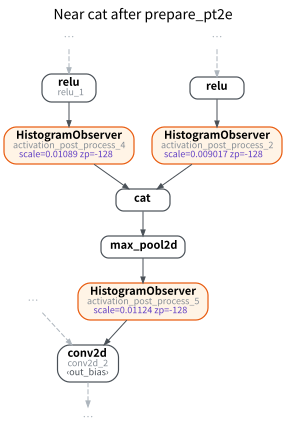

In [10]:
prepared2 = prepare_pt2e(gm2, q2)
with torch.no_grad():
    for _ in range(8):
        prepared2(torch.randn(4, 3, 16, 16))
draw(prepared2, focus=["cat", "max_pool2d"], hops=2, title="Near cat after prepare_pt2e")

**Answers 2 and 3**: in this environment, the two inputs of `cat` each use their own qparams (the two observers in the figure above have different scales),
and `max_pool2d` is not quantized either.

This is not by design but the quantizer silently failing. This project's M01 to M07 use the **torchao test version** of `XNNPACKQuantizer`
(`torchao.testing.pt2e._xnnpack_quantizer`, a copy torchao keeps for its own unit tests).
Its way of finding `cat` depends on `node.meta["source_fn_stack"]`, but nodes exported by torch 2.14 no longer have this field:


In [11]:
cat_node = next(n for n in gm2.graph.nodes if n.name == "cat")
print(sorted(cat_node.meta))
assert "source_fn_stack" not in cat_node.meta

['from_node', 'nn_module_stack', 'stack_trace', 'tensor_meta', 'torch_fn', 'val']


`max_pool2d` has no annotator of its own; in the last step it "shares qparams with its input". Its input `cat` is not annotated, so it is not annotated either.
conv, linear, and add match `node.target` directly, so they work as usual.
The `XNNPACKQuantizer` shipped with executorch does not have this problem; M08 compares the two.

## Summary

- prepare does two things: fold BN and insert observers according to the annotations. convert replaces observers with q/dq and stores the weight as an int8 constant.
- There is no quantization point between conv + relu; this is how PT2E expresses "fusion".
- Whether an op is quantized must be verified by dumping the annotations yourself; don't rely only on docs or articles.
